# 14 - NMR Petrophysics

**Part B - Petrophys Curriculum**

Nuclear Magnetic Resonance (NMR) logging measures the relaxation of hydrogen
protons in the pore fluid. Unlike density, neutron or sonic tools, the NMR
response is **independent of the rock matrix** - it "sees" only the fluids in
the pore space. That single property makes NMR the most direct downhole
measurement of porosity, pore-size distribution, bound versus movable fluid,
and (through empirical models) permeability.

This notebook walks through the `petrophys.nmr` toolkit end to end on the
bundled `nmr.csv` sample: the T2 distribution, the log-mean T2, the bound /
free-fluid split via a T2 cutoff, and the two workhorse NMR permeability
models (SDR and Timur-Coates).

## Learning goals

By the end of this notebook you will be able to:

- Load a pre-processed NMR log (T2-bin volumes + summary curves) into an
  `NMRData` container.
- Read and plot a **T2 distribution** and compute its **log-mean T2** (`T2lm`).
- Split porosity into **Bulk Volume Irreducible (BVI)** and **Free Fluid Index
  (FFI)** with a T2 cutoff, and understand why the cutoff differs between
  **clastics (~33 ms)** and **carbonates (~92 ms)**.
- Estimate permeability with the **SDR** ($k = C\,\phi^4\,T2_{lm}^2$) and
  **Timur-Coates** ($k = (\phi/C)^a (FFI/BVI)^b$) models, and compare them to a
  conventional Timur estimate.
- Compare **NMR porosity (MPHI)** against a density-neutron porosity.

## Why this matters (the physics)

After a polarizing pulse, hydrogen protons in the pore fluid relax back to
equilibrium with a **transverse relaxation time $T_2$**. In a water-wet rock the
dominant mechanism is *surface relaxation*, and to first order

$$\frac{1}{T_2} \approx \rho_2\,\frac{S}{V},$$

where $\rho_2$ is the surface relaxivity and $S/V$ is the pore surface-to-volume
ratio. Small pores have a **large** $S/V$ and relax **fast** (short $T_2$); large
pores relax slowly (long $T_2$). So the measured **T2 distribution is a proxy for
the pore-size distribution**:

- **Short $T_2$** -> tiny/clay-bound and capillary-bound water -> **irreducible** (BVI).
- **Long $T_2$** -> large pores holding **movable** (free) fluid (FFI).

A single **T2 cutoff** separates the two. The total area under the T2
distribution is the **NMR porosity (MPHI)** - matrix-independent, hence a
gold-standard porosity.

### Prerequisites
This notebook assumes you have worked through the Part A porosity (04) and
permeability (08) notebooks. Basic familiarity with porosity units (fractions
vs porosity units, "pu" = percent) is helpful.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.data import DATA_DIR
from petrophys.nmr import (
    NMRData,
    DEFAULT_T2_CENTERS,
    T2_CUTOFF_CLASTIC,
    T2_CUTOFF_CARBONATE,
    sdr_permeability,
    coates_permeability,
    t2lm_from_bins,
    bvi_from_bins,
    ffi_from_bins,
)

print('petrophys', petrophys.__version__)
print('DATA_DIR ->', DATA_DIR)
print('default T2 bin centres (ms):', DEFAULT_T2_CENTERS)
print('T2 cutoff clastic  :', T2_CUTOFF_CLASTIC, 'ms')
print('T2 cutoff carbonate:', T2_CUTOFF_CARBONATE, 'ms')

petrophys 0.1.0
DATA_DIR -> petrophys\data
default T2 bin centres (ms): [  4.   8.  16.  32.  64. 128. 256. 512.]
T2 cutoff clastic  : 32.0 ms
T2 cutoff carbonate: 92.0 ms


## 1. Load the NMR data

The bundled `nmr.csv` is a pre-processed NMR log with the standard column
layout:

| Column | Meaning |
|--------|---------|
| `Depth` | measured depth (ft) |
| `MPHI` | total NMR porosity, sum of all bins (porosity units, pu = %) |
| `P1 ... P8` | porosity volume in each of the 8 T2 bins (pu) |
| `MFFI` | Free Fluid Index (pu) |
| `MBVI` | Bulk Volume Irreducible (pu) |

The 8 bins map onto the default T2 centres `[4, 8, 16, 32, 64, 128, 256, 512]`
ms. `NMRData.from_csv` recognises this layout out of the box, so no column
mapping is needed.

In [2]:
raw = pd.read_csv(DATA_DIR / 'nmr.csv')
print('raw shape:', raw.shape)
print('columns   :', list(raw.columns))
raw.head()

raw shape: (51, 12)
columns   : ['Depth', 'MPHI', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'MFFI', 'MBVI']


,Depth,MPHI,P1,P2,P3,P4,P5,P6,P7,P8,MFFI,MBVI
0,7177.0,3.294,0.7960,0.6230,0.1180,0.0130,0.0160,0.172,0.5560,0.9980,1.756,1.5370
1,7177.5,3.002,0.3010,0.3500,0.2220,0.1540,0.2040,0.392,0.6140,0.7650,2.129,0.8730
2,7178.0,3.289,0.0620,0.2170,0.3430,0.3800,0.4260,0.528,0.6300,0.7020,2.668,0.6220
3,7178.5,4.568,0.0480,0.3030,0.6280,0.7910,0.7770,0.715,0.6670,0.6390,3.590,0.9790
4,7179.0,5.397,0.1835,0.3435,0.6465,0.9735,1.0485,0.902,0.7175,0.5825,4.224,1.1735


In [3]:
# from_csv defaults already match: depth_col='Depth', mphi_col='MPHI',
# bin_cols=['P1'..'P8'], mffi_col='MFFI', mbvi_col='MBVI', t2_cutoff=33->32ms clastic.
nmr = NMRData.from_csv(DATA_DIR / 'nmr.csv')
print('container        :', nmr)
print('n_samples        :', nmr.n_samples)
print('n_bins           :', nmr.n_bins)
print('depth range (ft) : %.1f - %.1f' % (nmr.top, nmr.bottom))
print('has T2 bins      :', nmr.has_bins)
print('active cutoff    : %.1f ms (clastic default)' % nmr.t2_cutoff)
print('MPHI median (pu) : %.2f' % np.nanmedian(nmr.mphi))

container        : NMRData(samples=51, depth=7177.0-7202.0, 8 T2 bins, MFFI, MBVI, cutoff=32.0ms)
n_samples        : 51
n_bins           : 8
depth range (ft) : 7177.0 - 7202.0
has T2 bins      : True
active cutoff    : 32.0 ms (clastic default)
MPHI median (pu) : 11.94


## 2. The T2 distribution

Each depth carries a full T2 distribution: the porosity (pu) assigned to each of
the 8 T2 bins. Plotting that distribution is the single most informative NMR
view - the *shape* immediately tells you whether the rock is bound-dominated
(short-T2 peak) or has a lot of movable fluid (long-T2 tail).

`nmr.bins` is the `(n_depth, n_bins)` array; `nmr.t2_distribution(i)` returns the
`(centres, volumes)` pair at one depth.

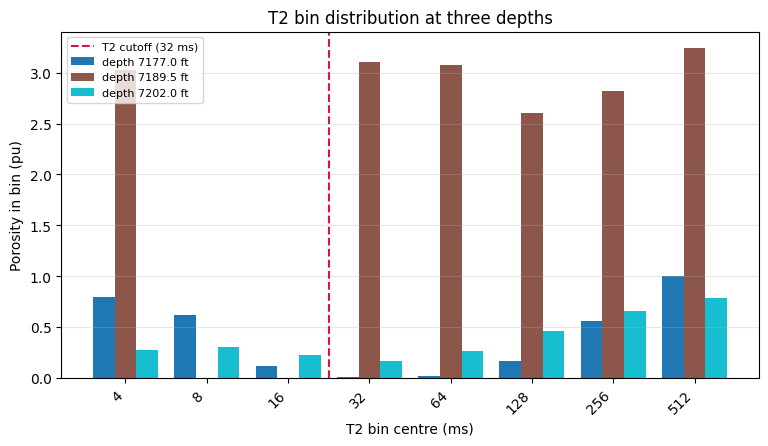

In [4]:
# Pick a shallow, a middle and a deep sample to contrast pore systems.
# Rendered with the library's create_bar_comparison (grouped bars).
from petrophys.visualization import create_bar_comparison

idx = [0, nmr.n_samples // 2, nmr.n_samples - 1]
categories = ['%g' % c for c in nmr.t2_centers]
grouped = {
    'depth %.1f ft' % nmr.depth[i]: nmr.t2_distribution(i)[1]
    for i in idx
}
fig, ax = create_bar_comparison(
    categories,
    grouped,
    xlabel='T2 bin centre (ms)',
    ylabel='Porosity in bin (pu)',
    title='T2 bin distribution at three depths',
    figsize=(9, 4.5),
)
# Mark the clastic T2 cutoff (styling on the library-returned axis).
cut_pos = np.searchsorted(nmr.t2_centers, nmr.t2_cutoff) - 0.5
ax.axvline(cut_pos, color='crimson', ls='--', lw=1.5, label='T2 cutoff (32 ms)')
ax.legend(fontsize=8)
plt.show()

The vertical dashed line marks the clastic T2 cutoff. Bins to the **left**
(short T2) are counted as **bound** water (BVI); bins to the **right** are
**free** fluid (FFI). A distribution that piles up on the left is a tight,
clay-rich or micro-porous rock; a long right-hand tail signals large,
well-connected pores.

### 2b. A T2 "waterfall" over the whole log

Stacking every depth's distribution as a heat map gives the classic NMR T2
panel - depth on the vertical axis, T2 time on the horizontal, colour = pore
volume.

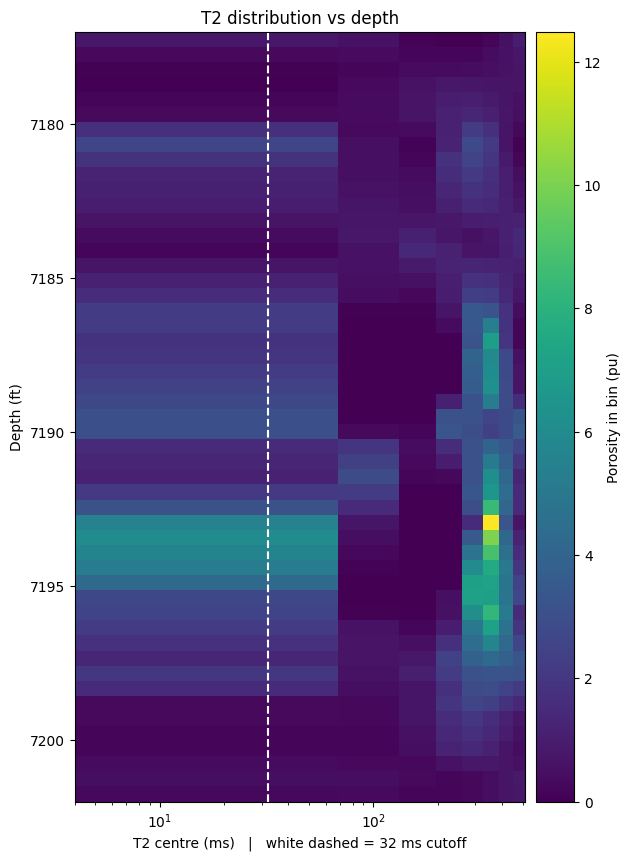

In [5]:
# T2 distribution vs depth, rendered by the library's create_heatmap helper
# (added to petrophys.visualization to cover 2-D intensity maps like an NMR
# T2 waterfall or a binned density crossplot).
from petrophys.visualization import create_heatmap

fig, ax = create_heatmap(
    nmr.bins,
    x=nmr.t2_centers,
    y=nmr.depth,
    cmap='viridis',
    invert_yaxis=True,
    xlabel='T2 centre (ms)   |   white dashed = 32 ms cutoff',
    ylabel='Depth (ft)',
    title='T2 distribution vs depth',
    colorbar_label='Porosity in bin (pu)',
)
# mark the clastic T2 cutoff on the returned axis
ax.axvline(nmr.t2_cutoff, color='white', ls='--', lw=1.5)
ax.set_xscale('log')
plt.show()


## 3. Log-mean T2 and the BVI / FFI split

Three scalar metrics summarise the distribution at each depth. `petrophys.nmr`
exposes them both as **standalone functions** (operate on raw bin arrays) and as
**`NMRData` methods** (use the container's centres and cutoff).

**Log-mean T2** (the geometric-mean relaxation time, in ms):

$$T2_{lm} = \exp\!\left(\frac{\sum_i \phi_i \ln T2_i}{\sum_i \phi_i}\right)$$

**BVI** = sum of bins with $T2 <$ cutoff (bound). **FFI** = sum of bins with
$T2 \ge$ cutoff (free). By construction $BVI + FFI$ equals
the bin sum (equal to MPHI up to file rounding).

In [6]:
# Standalone functions on the raw bin array:
t2lm_std = t2lm_from_bins(nmr.bins, DEFAULT_T2_CENTERS)
bvi_std = bvi_from_bins(nmr.bins, DEFAULT_T2_CENTERS, cutoff_ms=T2_CUTOFF_CLASTIC)
ffi_std = ffi_from_bins(nmr.bins, DEFAULT_T2_CENTERS, cutoff_ms=T2_CUTOFF_CLASTIC)

# Equivalent NMRData methods (use container cutoff):
t2lm = nmr.t2_lm()
bvi = nmr.bvi_from_bins()
ffi = nmr.ffi_from_bins()

print('T2lm  standalone vs method match:', np.allclose(t2lm_std, t2lm, equal_nan=True))
print('BVI   standalone vs method match:', np.allclose(bvi_std, bvi, equal_nan=True))
print('FFI   standalone vs method match:', np.allclose(ffi_std, ffi, equal_nan=True))
print()
print('T2lm  median (ms) : %.1f' % np.nanmedian(t2lm))
print('BVI   median (pu) : %.2f' % np.nanmedian(bvi))
print('FFI   median (pu) : %.2f' % np.nanmedian(ffi))
print('BVI+FFI vs MPHI   : %.3f vs %.3f (should match)'
      % (np.nanmedian(bvi + ffi), np.nanmedian(nmr.mphi)))

T2lm  standalone vs method match: True
BVI   standalone vs method match: True
FFI   standalone vs method match: True

T2lm  median (ms) : 69.6
BVI   median (pu) : 2.29
FFI   median (pu) : 10.08
BVI+FFI vs MPHI   : 11.942 vs 11.941 (should match)


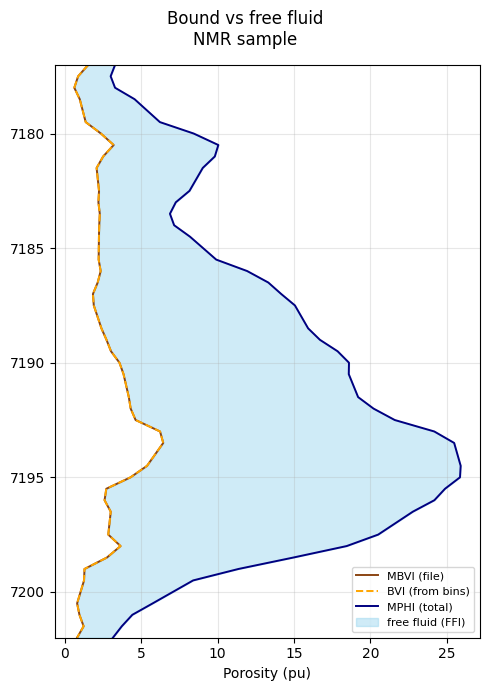

In [7]:
# Build a Well on the NMR depth grid so the petrophys log/crossplot plotters can
# render the NMR curves. Reused by the later permeability and porosity cells.
from petrophys.base.well import Well
from petrophys.visualization import LogPlot

nmr_well = Well(name='NMR sample')
nmr_well.depth = nmr.depth
nmr_well.depth_unit = 'ft'
nmr_well.add_curve('MPHI', nmr.mphi, unit='pu', description='NMR total porosity')
nmr_well.add_curve('MFFI', nmr.mffi, unit='pu', description='Free fluid index (file)')
nmr_well.add_curve('MBVI', nmr.mbvi, unit='pu', description='Bulk vol irreducible (file)')
nmr_well.add_curve('BVI_BINS', bvi, unit='pu', description='BVI from bins')

# Cross-check against the file's own MFFI / MBVI summary curves, via LogPlot.
lp = LogPlot(nmr_well, figsize=(5, 7))
lp.create_figure(1)
lp.add_curve(0, 'MBVI', color='saddlebrown', linewidth=1.4, label='MBVI (file)')
lp.add_curve(0, 'BVI_BINS', color='orange', linewidth=1.4, linestyle='--', label='BVI (from bins)')
lp.add_curve(0, 'MPHI', color='navy', linewidth=1.4, label='MPHI (total)')
lp.axes[0].set_xlabel('Porosity (pu)')
# Free-fluid (FFI) band = area between MBVI and MPHI. add_fill only fills to a
# scalar, so the two-curve band is drawn as styling on the library-returned axis.
lp.axes[0].fill_betweenx(nmr.depth, nmr.mbvi, nmr.mphi, color='skyblue', alpha=0.4,
                         label='free fluid (FFI)')
lp.axes[0].legend(fontsize=8, loc='lower right')
lp.set_depth_range(nmr.depth[0], nmr.depth[-1])
lp.add_title('Bound vs free fluid')
lp.show()

The bin-derived BVI tracks the file's MBVI closely - the small differences
vs the file's MBVI column are CSV rounding (~0.001 pu). The shaded band is the
**movable (free) fluid** - the part of porosity that can flow.

**Irreducible water saturation** follows directly: $S_{wirr} = BVI / MPHI$.

In [8]:
swirr = nmr.swirr_nmr()
print('NMR Swirr median : %.3f' % np.nanmedian(swirr))
print('NMR Swirr range  : %.3f - %.3f'
      % (np.nanmin(swirr), np.nanmax(swirr)))

NMR Swirr median : 0.213
NMR Swirr range  : 0.108 - 0.467


## 4. The T2 cutoff: clastics vs carbonates

The cutoff is **not** a universal constant - it depends on the pore system.

- **Clastics** (sandstones): the classic Gulf-of-Mexico value is **~33 ms**
  (the library uses 32 ms, which is one of the default T2 bin centres
  [4, 8, 16, 32, 64, ...]).
- **Carbonates**: intergranular + micro-porosity pushes the movable/bound
  boundary out to **~92 ms**.

Choosing the wrong cutoff shifts porosity between BVI and FFI, which directly
changes the Timur-Coates permeability (next section). Below we recompute the
split for a carbonate cutoff on the same rock.

In [9]:
bvi_clastic = nmr.bvi_from_bins(cutoff_ms=T2_CUTOFF_CLASTIC)
ffi_clastic = nmr.ffi_from_bins(cutoff_ms=T2_CUTOFF_CLASTIC)
bvi_carb = nmr.bvi_from_bins(cutoff_ms=T2_CUTOFF_CARBONATE)
ffi_carb = nmr.ffi_from_bins(cutoff_ms=T2_CUTOFF_CARBONATE)

tbl = pd.DataFrame({
    'cutoff (ms)': [T2_CUTOFF_CLASTIC, T2_CUTOFF_CARBONATE],
    'BVI median (pu)': [np.nanmedian(bvi_clastic), np.nanmedian(bvi_carb)],
    'FFI median (pu)': [np.nanmedian(ffi_clastic), np.nanmedian(ffi_carb)],
    'Swirr median': [np.nanmedian(bvi_clastic / nmr.mphi),
                     np.nanmedian(bvi_carb / nmr.mphi)],
})
print(tbl.to_string(index=False))
print()
print('-> A larger (carbonate) cutoff moves fluid from FFI into BVI,')
print('   raising apparent Swirr and lowering movable-fluid volume.')

 cutoff (ms)  BVI median (pu)  FFI median (pu)  Swirr median
        32.0            2.291           10.081       0.21337
        92.0            5.930            5.568       0.47541

-> A larger (carbonate) cutoff moves fluid from FFI into BVI,
   raising apparent Swirr and lowering movable-fluid volume.


## 5. NMR permeability models

Permeability cannot be measured directly by NMR, but two empirical models turn
the T2 metrics into a permeability estimate.

### SDR (Schlumberger-Doll Research)

$$k_{SDR} = C \cdot \phi^{4} \cdot T2_{lm}^{2}$$

Uses the **log-mean T2** - excellent in water-saturated rock, but $T2_{lm}$ is
biased by hydrocarbons (oil/gas relax differently), so SDR degrades in the pay.
$\phi$ is a **fraction** here; default $C = 4$ (Kenyon 1992).

### Timur-Coates

$$k_{TC} = \left(\frac{\phi}{C}\right)^{a}\left(\frac{FFI}{BVI}\right)^{b}$$

Uses the **free/bound ratio** instead of $T2_{lm}$, so it is far less sensitive
to hydrocarbon in the pores - the preferred model in reservoirs. Here $\phi$ is
in **pu**; defaults $C=10,\,a=4,\,b=2$.

In [10]:
# NMRData methods use MPHI internally (fraction for SDR, pu for Coates).
k_sdr = nmr.permeability_sdr()          # C=4 default
k_tc = nmr.permeability_coates()        # C=10, a=4, b=2 default

# The same numbers via the standalone functions, to show the plumbing. The
# Coates method uses the file's stored MFFI/MBVI internally, so we feed those
# (the bin-summed ffi/bvi would land ~0.25% away, from CSV rounding):
k_sdr_std = sdr_permeability(nmr.mphi / 100.0, nmr.t2_lm(), c=4.0)
k_tc_std = coates_permeability(nmr.mphi, nmr.mffi, nmr.mbvi, c=10.0, a=4.0, b=2.0)

print('SDR    method vs standalone match:', np.allclose(k_sdr, k_sdr_std, equal_nan=True))
print('Coates method vs standalone match:', np.allclose(k_tc, k_tc_std, equal_nan=True))
print()
print('k_SDR    median : %8.2f mD' % np.nanmedian(k_sdr))
print('k_Coates median : %8.2f mD' % np.nanmedian(k_tc))

SDR    method vs standalone match: True
Coates method vs standalone match: True

k_SDR    median :     4.88 mD
k_Coates median :    84.81 mD


### Compare NMR permeability to a conventional estimate

The **Timur** equation is the classic *log-only* permeability transform - it
needs only porosity and irreducible water saturation:

$$k_{Timur} = a\,\frac{\phi^{b}}{S_{wirr}^{c}}$$

We feed it the **NMR** porosity and **NMR** Swirr, so all three curves come from
the same nmr.csv - a genuine apples-to-apples comparison of the models rather
than of the input data.

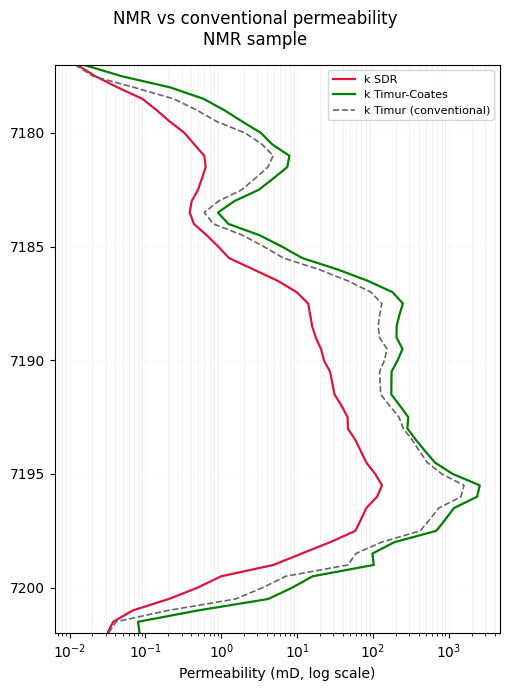

        model  median k (mD)  min k (mD)  max k (mD)
          SDR       4.880367    0.012533  131.583313
 Timur-Coates      84.805965    0.015367 2556.502736
Timur (conv.)      46.227864    0.011847 1585.061031


In [11]:
from petrophys.petrophysics.permeability import timur

phi_frac = nmr.mphi / 100.0
k_timur = timur(phi_frac, swirr)      # default a=0.136, b=4.4, c=2.0

# Add the three permeability logs to the shared NMR well and plot via LogPlot.
nmr_well.add_curve('KSDR', k_sdr, unit='mD', description='SDR permeability')
nmr_well.add_curve('KTIM', k_tc, unit='mD', description='Timur-Coates permeability')
nmr_well.add_curve('K_TIMUR', k_timur, unit='mD', description='Conventional Timur permeability')

lp = LogPlot(nmr_well, figsize=(5.2, 7))
lp.create_figure(1)
lp.add_curve(0, 'KSDR', color='crimson', linewidth=1.6, log_scale=True, label='k SDR')
lp.add_curve(0, 'KTIM', color='green', linewidth=1.6, log_scale=True, label='k Timur-Coates')
lp.add_curve(0, 'K_TIMUR', color='0.4', linewidth=1.2, linestyle='--', log_scale=True,
             label='k Timur (conventional)')
lp.axes[0].set_xlabel('Permeability (mD, log scale)')
lp.axes[0].grid(True, which='both', color='0.92', lw=0.5)
lp.set_depth_range(nmr.depth[0], nmr.depth[-1])
lp.add_title('NMR vs conventional permeability')
lp.show()

summary = pd.DataFrame({
    'model': ['SDR', 'Timur-Coates', 'Timur (conv.)'],
    'median k (mD)': [np.nanmedian(k_sdr), np.nanmedian(k_tc), np.nanmedian(k_timur)],
    'min k (mD)': [np.nanmin(k_sdr), np.nanmin(k_tc), np.nanmin(k_timur)],
    'max k (mD)': [np.nanmax(k_sdr), np.nanmax(k_tc), np.nanmax(k_timur)],
})
print(summary.to_string(index=False))

The three curves agree on the *shape* of the permeability profile but differ
by up to an order of magnitude in absolute value - a normal state of affairs
before **core calibration**. In practice you would fit the model constant
($C$ for SDR, or $C,a,b$ for Coates) to core plug permeability; `NMRData`
provides `calibrate_sdr()` / `calibrate_coates()` for exactly that (not shown
here, as the sample carries no core plugs).

**Which model to trust?**

| Situation | Prefer |
|-----------|--------|
| Water zone, good $T2_{lm}$ | SDR (simplest, robust) |
| Hydrocarbon-bearing pay | Timur-Coates (uses FFI/BVI, HC-insensitive) |
| Only logs, no NMR | conventional Timur |

## 6. NMR porosity vs density-neutron porosity

NMR porosity (MPHI) is **matrix-independent**: it counts fluid hydrogen and
needs no matrix-density assumption. A **density-neutron** porosity, by contrast,
must assume a matrix density ($\rho_{ma}$) and can be pushed high by clay-bound
water or gas cross-over.

The bundled `nmr.csv` has no companion RHOB/NPHI curves, so below we build a
small **clearly-labelled illustrative** density-neutron porosity around the NMR
trend to *demonstrate the comparison workflow* - it is synthetic, not measured.

In [12]:
# --- ILLUSTRATIVE density-neutron porosity (SYNTHETIC, for teaching only) ---
# Density porosity: phiD = (rho_ma - rho_b) / (rho_ma - rho_fl)
# Here we fabricate a RHOB trend loosely consistent with MPHI, add a slight
# clay-bound-water high-bias to NPHI, then average -> phi_ND.
rng = np.random.default_rng(42)
rho_ma, rho_fl = 2.65, 1.0                         # sandstone matrix, fresh water
phi_true = nmr.mphi / 100.0
rhob = rho_ma - phi_true * (rho_ma - rho_fl) + rng.normal(0, 0.02, nmr.n_samples)
nphi = phi_true + 0.02 + rng.normal(0, 0.015, nmr.n_samples)   # +2 pu shale effect
phi_d = (rho_ma - rhob) / (rho_ma - rho_fl)
phi_nd = 0.5 * (phi_d + nphi)                      # simple average
print('NOTE: RHOB/NPHI above are SYNTHETIC illustrative curves.')
print('MPHI (NMR)  median : %.3f' % np.nanmedian(phi_true))
print('phi_ND      median : %.3f' % np.nanmedian(phi_nd))

NOTE: RHOB/NPHI above are SYNTHETIC illustrative curves.
MPHI (NMR)  median : 0.119
phi_ND      median : 0.123


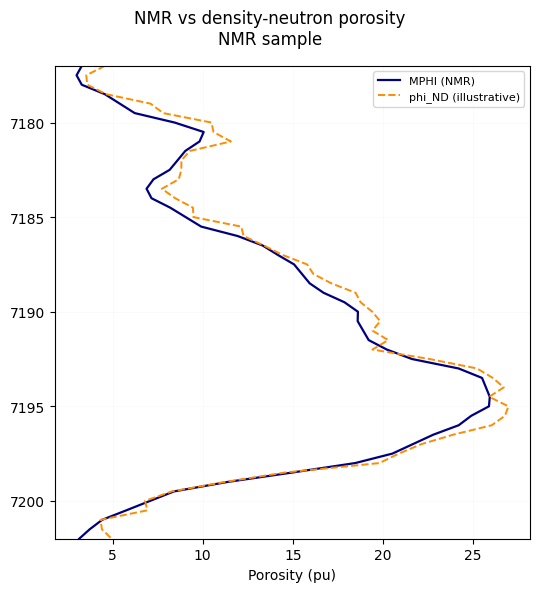

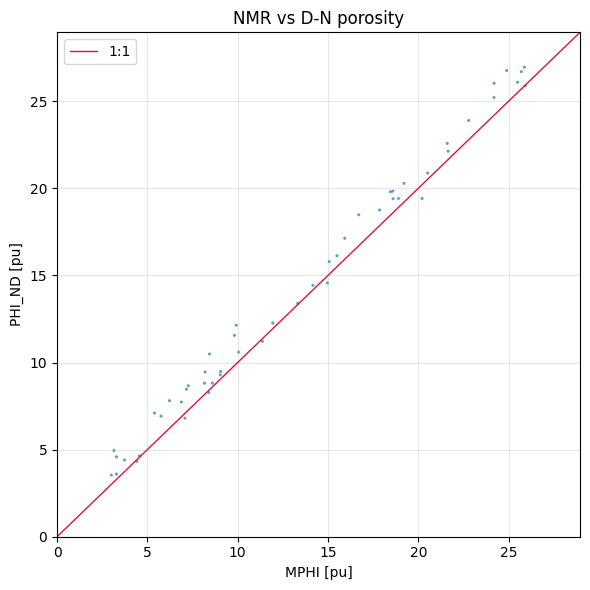

Median (phi_ND - MPHI) = +0.80 pu
-> The D-N average reads high here: clay-bound water inflates NPHI,
   whereas NMR sees only the true fluid-filled porosity.


In [13]:
from petrophys.visualization import create_crossplot

# Add porosity curves (in pu) to the shared NMR well. MPHI already exists (pu);
# attach the illustrative D-N porosity as PHI_ND in pu to match units.
nmr_well.add_curve('PHI_ND', phi_nd * 100, unit='pu', description='Illustrative D-N porosity')

# Left panel: NMR MPHI vs phi_ND depth track (library LogPlot).
lp = LogPlot(nmr_well, figsize=(5.5, 6))
lp.create_figure(1)
lp.add_curve(0, 'MPHI', color='navy', linewidth=1.6, label='MPHI (NMR)')
lp.add_curve(0, 'PHI_ND', color='darkorange', linewidth=1.4, linestyle='--',
             label='phi_ND (illustrative)')
lp.axes[0].set_xlabel('Porosity (pu)')
lp.axes[0].grid(True, color='0.92', lw=0.5)
lp.set_depth_range(nmr.depth[0], nmr.depth[-1])
lp.add_title('NMR vs density-neutron porosity')
lp.show()

# Right panel: cross-plot MPHI vs phi_ND with the 1:1 line (library CrossPlot).
lims = [0.0, max(np.nanmax(phi_true), np.nanmax(phi_nd)) * 100 + 2]
cp = create_crossplot(
    nmr_well, 'MPHI', 'PHI_ND',
    title='NMR vs D-N porosity',
    figsize=(6, 6),
    xlim=tuple(lims), ylim=tuple(lims),
)
cp.add_line(lims, lims, color='crimson', label='1:1')
cp.show()

bias = np.nanmedian(phi_nd - phi_true) * 100
print('Median (phi_ND - MPHI) = %+.2f pu' % bias)
print('-> The D-N average reads high here: clay-bound water inflates NPHI,')
print('   whereas NMR sees only the true fluid-filled porosity.')

## 7. Export all derived results

`NMRData.to_dataframe()` bundles the inputs and every derived curve (T2lm,
K_SDR, K_COATES, pore radius, Swirr) into one table for QC or hand-off.

In [14]:
out = nmr.to_dataframe()
print('exported columns:', list(out.columns))
out.head()

exported columns: ['DEPTH', 'MPHI', 'MFFI', 'MBVI', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'T2LM', 'K_SDR', 'K_COATES', 'PORE_R', 'SWIRR']


,DEPTH,MPHI,MFFI,MBVI,P1,P2,P3,P4,P5,P6,P7,P8,T2LM,K_SDR,K_COATES,PORE_R,SWIRR
0,7177.0,3.294,1.756,1.5370,0.7960,0.6230,0.1180,0.0130,0.0160,0.172,0.5560,0.9980,51.587259,0.012533,0.015367,1.547618,0.466606
1,7177.5,3.002,2.129,0.8730,0.3010,0.3500,0.2220,0.1540,0.2040,0.392,0.6140,0.7650,81.803874,0.021740,0.048302,2.454116,0.290806
2,7178.0,3.289,2.668,0.6220,0.0620,0.2170,0.3430,0.3800,0.4260,0.528,0.6300,0.7020,96.114276,0.043241,0.215301,2.883428,0.189115
3,7178.5,4.568,3.590,0.9790,0.0480,0.3030,0.6280,0.7910,0.7770,0.715,0.6670,0.6390,72.457936,0.091440,0.585501,2.173738,0.214317
4,7179.0,5.397,4.224,1.1735,0.1835,0.3435,0.6465,0.9735,1.0485,0.902,0.7175,0.5825,64.441224,0.140928,1.099237,1.933237,0.217436


## Pitfalls & parameter choices

- **Porosity units.** SDR wants $\phi$ as a **fraction**; Timur-Coates wants
  **pu (%)**. The `NMRData` methods handle the conversion internally - only worry
  about it when calling the standalone `sdr_permeability` / `coates_permeability`
  functions directly.
- **T2 cutoff is lithology-dependent.** 33 ms clastic vs 92 ms carbonate is a
  starting point; ideally you calibrate it against core BVI. A wrong cutoff
  mis-splits BVI/FFI and skews Timur-Coates permeability.
- **SDR in hydrocarbons.** $T2_{lm}$ is biased by oil/gas relaxation, so SDR
  under-reads permeability in pay. Use Timur-Coates there.
- **Model constants need core.** The default $C$, $a$, $b$ are literature
  averages. Always calibrate to core plugs when available
  (`nmr.calibrate_sdr` / `nmr.calibrate_coates`).
- **BVI = MPHI - MFFI.** When you only load summary curves (no bins), NMRData
  can still derive Swirr and Coates permeability from MPHI/MFFI/MBVI.

## Recap

- The **T2 distribution** is a matrix-independent pore-size proxy; its total area
  is **MPHI**, the gold-standard porosity.
- A **T2 cutoff** splits porosity into **bound (BVI)** and **free (FFI)** fluid;
  the cutoff is ~33 ms for clastics, ~92 ms for carbonates.
- **$T2_{lm}$**, **BVI**, and **FFI** feed two permeability models: **SDR**
  ($C\phi^4 T2_{lm}^2$) for water zones and **Timur-Coates**
  ($(\phi/C)^a(FFI/BVI)^b$) for pay.
- NMR permeability estimates track the conventional Timur shape but must be
  **core-calibrated** for absolute accuracy.
- NMR porosity is cleaner than density-neutron because it ignores the matrix and
  is less fooled by clay-bound water.

## Try it yourself

> **Exercise 1.** Recompute `k_Coates` using the **carbonate** cutoff (92 ms) for
> BVI/FFI and overlay it on the clastic-cutoff result. How much does the median
> permeability move?
>
> **Exercise 2.** Sweep the SDR constant `c` over `[2, 4, 10]` with
> `nmr.permeability_sdr(c=...)` and plot the three curves. Which best matches the
> Timur-Coates profile?
>
> **Exercise 3.** Call `nmr.pore_size(surface_relaxivity=15)` and plot the modal
> pore radius against depth. Where are the largest pores?

## What's next

Continue with **15 - Capillary Pressure & Saturation-Height**, where the
bound/free-fluid ideas from NMR reappear as capillary equilibrium above the
free-water level, and we predict water saturation from porosity, permeability
and height.